<a href="https://colab.research.google.com/github/SarthC/AIML-LAB-/blob/main/Assignment_2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
graph = {
    'A': {'B': 4, 'C': 7},
    'B': {'A': 4, 'D': 5},
    'C': {'A': 7},
    'D': {'B': 5},
}
heuristic = {
    'A': 11,
    'B': 6,
    'C': 5,
    'D': 7,
}

def a_star(start, goal):
    open_list = [start]
    cost = {start: 0}

    while open_list:

        current = open_list[0]
        for node in open_list:
            if cost[node] + heuristic[node] < cost[current] + heuristic[current]:
                current = node

        if current == goal:
            print("Goal Reached")
            print("Total Cost =", cost[current])
            return

        open_list.remove(current)


        neighbors = graph.get(current, {})

        for neighbour in neighbors:

            weight = neighbors[neighbour]
            new_cost = cost[current] + weight

            if neighbour not in cost or new_cost < cost[neighbour]:
                cost[neighbour] = new_cost
                if neighbour not in open_list:
                    open_list.append(neighbour)

a_star('A', 'D')

Goal Reached
Total Cost = 9


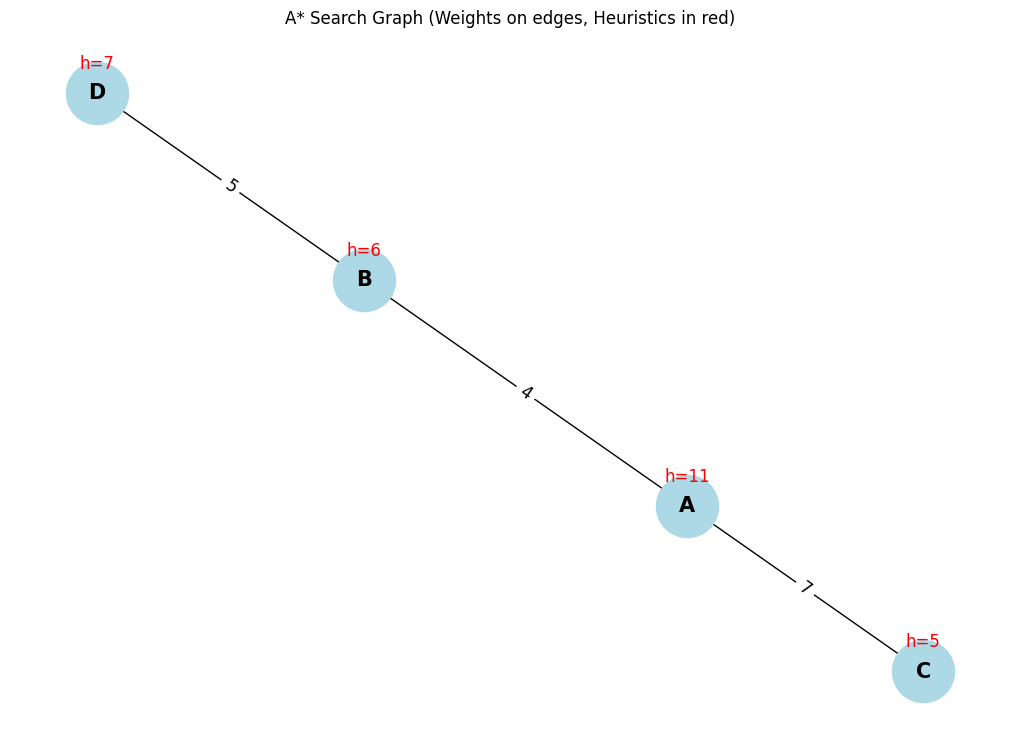

In [ ]:
import matplotlib.pyplot as plt
import networkx as nx

def plot_search_graph(graph, heuristic):
    G = nx.Graph()

    for node, neighbors in graph.items():
        for neighbor, weight in neighbors.items():
            G.add_edge(node, neighbor, weight=weight)

    pos = nx.spring_layout(G, seed=42)
    plt.figure(figsize=(10, 7))

    nx.draw(G, pos, with_labels=True, node_size=2000, node_color='lightblue', font_size=15, font_weight='bold')


    edge_labels = nx.get_edge_attributes(G, 'weight')
    nx.draw_networkx_edge_labels(G, pos, edge_labels=edge_labels, font_size=12)

    h_labels = {node: f"h={val}" for node, val in heuristic.items()}
    pos_higher = {k: (v[0], v[1]+0.1) for k, v in pos.items()}
    nx.draw_networkx_labels(G, pos_higher, labels=h_labels, font_color='red')

    plt.title("A* Search Graph (Weights on edges, Heuristics in red)")
    plt.show()

plot_search_graph(graph, heuristic)